# E.1 A favored allele in a finite population

An allele improves expected reproductive contribution. Must its frequency rise in the next generation?

Let $p$ be the allele-A frequency and $q=1-p$. Under Hardy–Weinberg equilibrium, $AA$, $Aa$, and $aa$ have frequencies $p^2$, $2pq$, and $q^2$. Give these genotypes relative fitnesses $w_{AA}$, $w_{Aa}$, and $w_{aa}$. Their weighted contributions give

$$\bar w=p^2w_{AA}+2pqw_{Aa}+q^2w_{aa},\qquad p_s=\frac{p^2w_{AA}+pqw_{Aa}}{\bar w}.$$

Selection changes the chance that a new copy is A. Finite sampling still chooses the actual count: $K'\mid p_s\sim\operatorname{Binomial}(2N_e,p_s)$.


## Predict one generation

Use $p=0.10$ and $(w_{AA},w_{Aa},w_{aa})=(1.10,1.05,1.00)$. We expect $p_s>0.10$. In a small population, some realized counts should nevertheless give a lower frequency. This is an original one-population example, not the two-region HbS homework.


In [1]:
library(hpgR)

p <- 0.10
w <- c(AA = 1.10, Aa = 1.05, aa = 1.00)
p_s <- selectedFrequency(p, w)
stopifnot(p_s > p, abs(selectedFrequency(p, c(1, 1, 1)) - p) < 1e-12)
c(start = p, selectedFrequency = p_s)


start selectedFrequency.AA 
           0.1000000            0.1044554

## Draw the next generation many times

The same $p_s$ can lead to different outcomes. Compare $N_e=20$ and $N_e=200$ while holding fitness fixed. The binomial model gives both the distribution and the exact probability of a one-generation decline.


Ne20     Ne200 
0.3872830 0.3615654

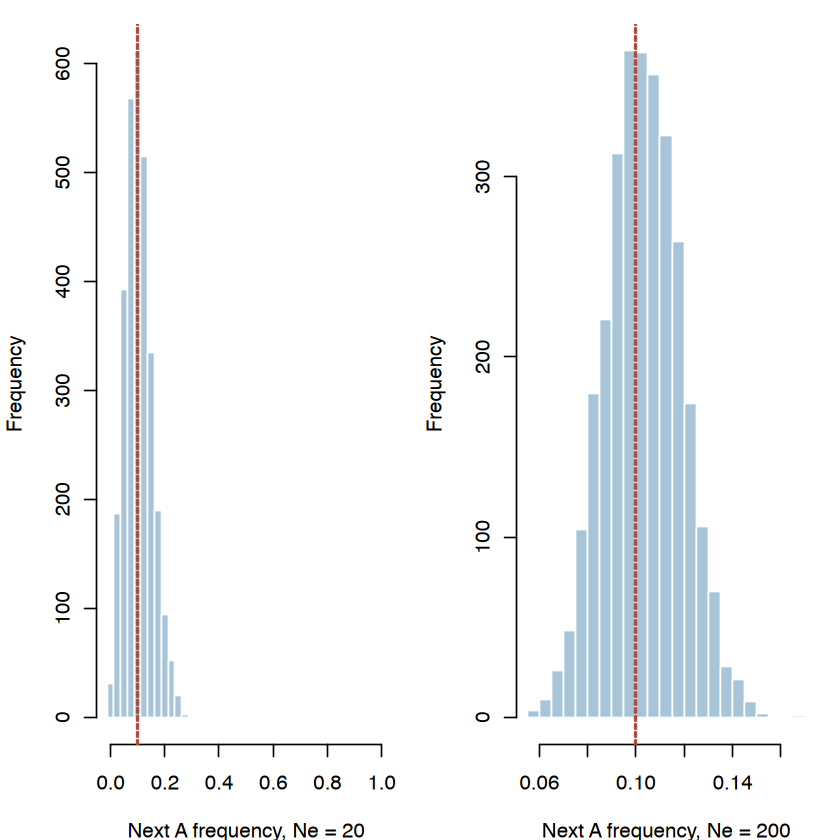

In [2]:
set.seed(11001)
small <- rbinom(3000, size = 40, prob = p_s) / 40
large <- rbinom(3000, size = 400, prob = p_s) / 400
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 1, 1))
hist(small, breaks = seq(-0.0125, 1.0125, by = 0.025),
     col = '#A7C4D9', border = 'white', xlab = 'Next A frequency, Ne = 20', main = '')
abline(v = p, lty = 2, col = '#B44A3A', lwd = 2)
hist(large, breaks = 35, col = '#A7C4D9', border = 'white',
     xlab = 'Next A frequency, Ne = 200', main = '')
abline(v = p, lty = 2, col = '#B44A3A', lwd = 2)
par(old_par)
c(Ne20 = selectionDeclineProbability(20, p, p_s), Ne200 = selectionDeclineProbability(200, p, p_s))


## What to remember

Fitness changes the sampling probability; drift chooses a count. Selection predicts a direction on average, not every realized step. The importance of a fixed fitness difference depends on effective population size.

**Sources.** Pritchard, *An Owner's Guide to the Human Genome*, Section 2.5; Gorroochurn, *Population Genetics Notes*, Sections 5.5–5.7. The fitness vector and simulation are original teaching values (seed 11001); they differ from Homework 11's HbS values.
